In [1]:
import pandas as pd 
from sklearn.cluster import KMeans 
from sklearn.preprocessing import MinMaxScaler 
from sklearn.metrics import silhouette_score 
import matplotlib.pyplot as plt 

data = pd.read_csv("Mall_customers.csv")
data

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
...,...,...,...,...,...
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18


In [2]:
data.columns

Index(['CustomerID', 'Gender', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)'],
      dtype='object')

In [4]:
x = data[['Annual Income (k$)','Spending Score (1-100)']]

scaler = MinMaxScaler()
x_scale = scaler.fit_transform(x)
x_scale

array([[0.        , 0.3877551 ],
       [0.        , 0.81632653],
       [0.00819672, 0.05102041],
       [0.00819672, 0.7755102 ],
       [0.01639344, 0.39795918],
       [0.01639344, 0.76530612],
       [0.02459016, 0.05102041],
       [0.02459016, 0.94897959],
       [0.03278689, 0.02040816],
       [0.03278689, 0.7244898 ],
       [0.03278689, 0.13265306],
       [0.03278689, 1.        ],
       [0.04098361, 0.14285714],
       [0.04098361, 0.7755102 ],
       [0.04098361, 0.12244898],
       [0.04098361, 0.79591837],
       [0.04918033, 0.34693878],
       [0.04918033, 0.66326531],
       [0.06557377, 0.28571429],
       [0.06557377, 0.98979592],
       [0.07377049, 0.34693878],
       [0.07377049, 0.73469388],
       [0.08196721, 0.04081633],
       [0.08196721, 0.73469388],
       [0.10655738, 0.13265306],
       [0.10655738, 0.82653061],
       [0.10655738, 0.31632653],
       [0.10655738, 0.6122449 ],
       [0.1147541 , 0.30612245],
       [0.1147541 , 0.87755102],
       [0.

Text(0, 0.5, 'wcss (inertia)')

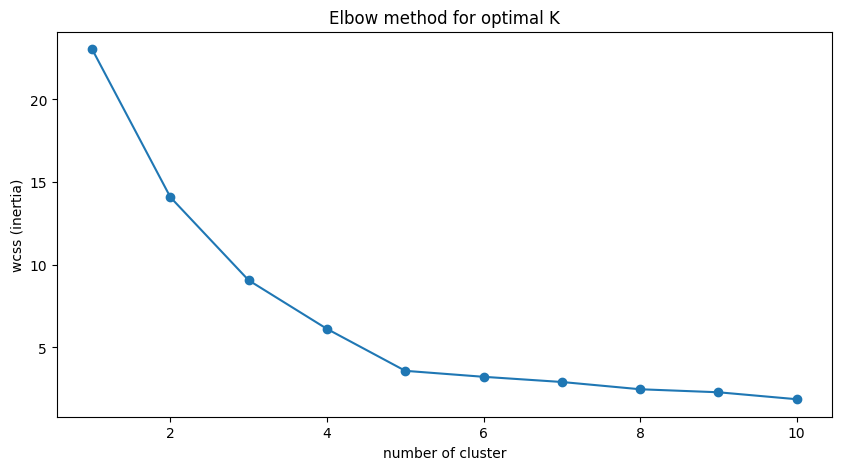

In [5]:
wcss = []
for i in range(1 , 11):
    kmeans = KMeans(n_clusters=i, random_state=42)
    kmeans.fit(x_scale)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(10,5))
plt.plot(range(1,11), wcss, marker="o")
plt.title("Elbow method for optimal K")
plt.xlabel("number of cluster")
plt.ylabel("wcss (inertia)")

In [6]:
k = 5 
kmeans = KMeans(n_clusters=k, init = "k-means++", n_init=10, max_iter=300, random_state=42)
data["Cluster"] = kmeans.fit_predict(x_scale)
data.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,0
2,3,Female,20,16,6,4
3,4,Female,23,16,77,0
4,5,Female,31,17,40,4


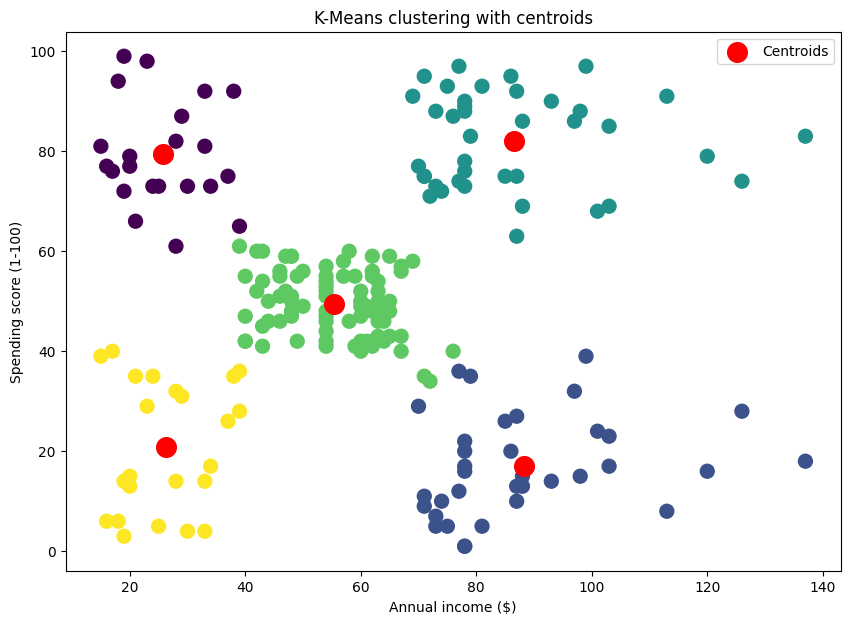

In [9]:
centroids = kmeans.cluster_centers_
centroids_original = scaler.inverse_transform(centroids)

plt.figure(figsize=(10,7))
plt.scatter(data["Annual Income (k$)"], 
            data["Spending Score (1-100)"], 
            c = data["Cluster"],
            cmap = "viridis",
            s = 100)
plt.scatter(centroids_original[:, 0], 
            centroids_original[:, 1], 
            s=200, 
            c = "red",
            label = "Centroids")
plt.xlabel("Annual income ($)")
plt.ylabel("Spending score (1-100)")
plt.title("K-Means clustering with centroids")
plt.legend()
plt.show()

In [12]:
centroids_original

array([[25.72727273, 79.36363636],
       [88.2       , 17.11428571],
       [86.53846154, 82.12820513],
       [55.2962963 , 49.51851852],
       [26.30434783, 20.91304348]])

In [11]:
data_1 = data[data["Cluster"] == 1]
data_1

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
124,125,Female,23,70,29,1
128,129,Male,59,71,11,1
130,131,Male,47,71,9,1
134,135,Male,20,73,5,1
136,137,Female,44,73,7,1
138,139,Male,19,74,10,1
140,141,Female,57,75,5,1
144,145,Male,25,77,12,1
146,147,Male,48,77,36,1
148,149,Female,34,78,22,1
